In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm, neighbors, ensemble
from sklearn.metrics import accuracy_score, confusion_matrix
from tensorflow.keras.datasets import mnist


In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("Training data shape:", x_train.shape)
print("Test data shape:", x_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training data shape: (60000, 28, 28)
Test data shape: (10000, 28, 28)


In [ ]:
x_train_flat = x_train.reshape(-1, 28*28) / 255.0
x_test_flat = x_test.reshape(-1, 28*28) / 255.0


In [ ]:
classifiers = {
    "SVM": svm.SVC(kernel='rbf', gamma='scale'),
    "KNN": neighbors.KNeighborsClassifier(n_neighbors=5),
    "RandomForest": ensemble.RandomForestClassifier(n_estimators=100)
}


In [ ]:
best_acc = 0
best_model = None


for name, clf in classifiers.items():
    print(f"\nTraining {name}...")
    clf.fit(x_train_flat, y_train)           # Train model
    y_pred = clf.predict(x_test_flat)        # Test model
    acc = accuracy_score(y_test, y_pred)     # Calculate accuracy
    print(f"{name} Test Accuracy: {acc:.4f}")

    if acc > best_acc:                       # Pick best model
        best_acc = acc
        best_model = clf
        best_model_name = name



Training SVM...
SVM Test Accuracy: 0.9792

Training KNN...
KNN Test Accuracy: 0.9688

Training RandomForest...
RandomForest Test Accuracy: 0.9699


In [ ]:
print(f"\n Best Model: {best_model_name} with Accuracy: {best_acc:.4f}")



 Best Model: SVM with Accuracy: 0.9792


In [ ]:
predictions = best_model.predict(x_test_flat)


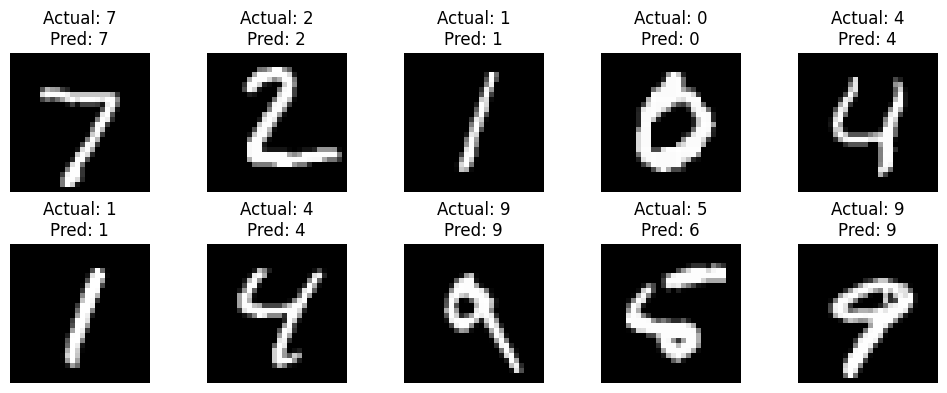

In [ ]:
plt.figure(figsize=(10,4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Actual: {y_test[i]}\nPred: {predictions[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()
